In [1]:
import math
import os
import re
import time
import gc
from collections import Counter, deque
from functools import lru_cache

import category_encoders as ce
import lightgbm as lgb

# Если будете у себя запускать, обязательно устанавливайте подобным образом: "pip install "llvmlite<0.45" "numba<0.62" lleaves", иначе она подтянет более новую версию llvmlite и упадет.
import lleaves

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from scipy.stats import ks_2samp
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from tqdm import tqdm

from IPython.display import display

/home/akastark/projects/ml_final/myenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Итотовая работа по ML
- Подробности на странице на платформе
- Данные для этой работы - это датасет с бинарной целевой переменной. Данные доступны по ссылке на платформе.


Вот описание данных:

**Данные по оттоку клиентов**
- client_id - уникальный id клиента
- регион - локация клиента
- использование - использование мобильной связи
- сумма - сумма пополнения баланса
- частота_пополнения - сколько раз клиент пополнял аккаунт
- доход - доход с одного клиента в месяц
- сегмент_arpu - выручка за квартал
- частота - сколько раз клиент приносил прибыль
- объем_данных - число раз, когда клиент делал подключение
- on_net - число звонков внутри сети
- продукт_1 - тариф 1
- продукт_2 - тариф 2
- зона_1 - звонки из гео-области 1
- зона_2 - звонки из гео-области 2
- mrg_ - флаг
- секретный_скор - некоторый модельный скор клиента
- pack - самый активный пакет клиента
- pack_freq - частота активации пакета pack
- binary_target - флаг оттока клиента

In [2]:
path_data = './'

# не меняйте название переменных train и test - в которых лежат датасеты train.csv и test_full.csv соответсвенно
# эти файлы будут участвовать в тестировании работы

train = pd.read_csv(path_data + 'train.csv')

# test датасет запрещается видоизменять - применять к нему какую либо логику трансформации
# можно видоизменять входные данные внутри функции def get_score(dict_input) (смотри ниже)

test = pd.read_csv(path_data + 'test_full.csv')

## Место для вашего кода ↓↓↓

## Обучение модели / написание вспомогательно кода ↓↓↓

### Парсинг тарифа (pack)

In [3]:
train['pack'].head(3)

0            _output-_сеть 500 (условие) 2000f;5d
1    тариф_a 250 (условие) _безлим_c_output_сутки
2                                             NaN
Name: pack, dtype: str

Вытащим фичи из столбца pack.

In [4]:
def parse_pack(s):
    if s is None or pd.isna(s) or s == '' or s == 'no_pack':
        return {
            'pack_type':       'no_pack',
            'pack_segment':    'no_pack',
            'pack_direction':  'no_pack',
            'pack_period':     'no_pack',
            'pack_main_num':   np.nan,
            'pack_traffic_mb': np.nan,
            'pack_duration_d': np.nan,
            'pack_unlim':      0,
            'pack_has_cond':   0,
            'pack_is_promo':   0,
            'pack_is_vas':     0,
            'pack_is_b2b':     0,
            'pack_n_tokens':   0,
        }

    if pd.isna(s) or s == '' or s == 'no_pack':
        return {
            'pack_type':       'no_pack',
            'pack_segment':    'no_pack',
            'pack_direction':  'no_pack',
            'pack_period':     'no_pack',
            'pack_main_num':   np.nan,
            'pack_traffic_mb': np.nan,
            'pack_duration_d': np.nan,
            'pack_unlim':      0,
            'pack_has_cond':   0,
            'pack_is_promo':   0,
            'pack_is_vas':     0,
            'pack_is_b2b':     0,
            'pack_n_tokens':   0,
        }

    s_low = s.lower()
    out = {}

    # --- 1. Сегмент: B2B / VAS / promo / regular ---
    is_b2b = bool(re.search(r'корп|b2b|cpe|rent', s_low))
    is_vas = bool(re.search(r'\bvas\b|ivr', s_low))
    is_promo = bool(re.search(r'promo|промо|mromo|секрет', s_low))
    is_soc = 'соц' in s_low

    out['pack_is_b2b'] = int(is_b2b)
    out['pack_is_vas'] = int(is_vas)
    out['pack_is_promo'] = int(is_promo)

    if is_b2b:
        out['pack_segment'] = 'b2b'
    elif is_vas:
        out['pack_segment'] = 'vas'
    elif is_soc:
        out['pack_segment'] = 'social'
    elif is_promo:
        out['pack_segment'] = 'promo'
    else:
        out['pack_segment'] = 'regular'

    # --- 2. Тип услуги ---
    if 'тариф' in s_low:
        out['pack_type'] = 'tariff'
    elif 'трафик' in s_low or re.search(r'\d+\s*(mb|gb)', s_low):
        out['pack_type'] = 'traffic'
    elif '_сеть' in s_low or 'сеть' in s_low:
        out['pack_type'] = 'network'
    elif is_vas:
        out['pack_type'] = 'vas'
    elif is_b2b:
        out['pack_type'] = 'b2b'
    elif is_promo:
        out['pack_type'] = 'promo'
    else:
        out['pack_type'] = 'other'

    # --- 3. Направление ---
    has_in = 'input' in s_low
    has_out = 'output' in s_low
    if has_in and has_out:
        out['pack_direction'] = 'both'
    elif has_in:
        out['pack_direction'] = 'input'
    elif has_out:
        out['pack_direction'] = 'output'
    else:
        out['pack_direction'] = 'none'

    # --- 4. Периодичность подписки ---
    if 'weekly' in s_low or 'недел' in s_low:
        period = 'weekly'
    elif '-каждый' in s_low or 'каждый' in s_low:
        period = 'recurring'
    elif 'e-день' in s_low or 'сутки' in s_low or re.search(r'\b1\s*d\b', s_low):
        period = 'daily'
    elif 'monthly' in s_low or 'месяц' in s_low:
        period = 'monthly'
    elif re.search(r'\b\d+\s*d\b', s_low):
        period = 'multi_day'
    else:
        period = 'none'
    out['pack_period'] = period

    # --- 5. Главное число ---
    main_match = re.search(r'(\d+)', s)
    out['pack_main_num'] = float(main_match.group(1)) if main_match else np.nan

    # --- 6. Трафик ---
    traffic_mb = np.nan
    m = re.search(r'(\d+)\s*gb', s_low)
    if m:
        traffic_mb = float(m.group(1)) * 1024
    else:
        m = re.search(r'(\d+)\s*mb', s_low)
        if m:
            traffic_mb = float(m.group(1))
    out['pack_traffic_mb'] = traffic_mb

    # --- 7. Длительность в днях ---
    duration_d = np.nan
    m = re.search(r'(\d+)\s*d\b', s_low)
    if m:
        duration_d = float(m.group(1))
    elif 'сутки' in s_low or 'e-день' in s_low:
        duration_d = 1.0
    elif 'weekly' in s_low or 'недел' in s_low:
        duration_d = 7.0
    elif 'monthly' in s_low or 'месяц' in s_low:
        duration_d = 30.0
    out['pack_duration_d'] = duration_d

    # --- 8. Безлимит / условие ---
    out['pack_unlim'] = int('безлим' in s_low)
    out['pack_has_cond'] = int('(условие)' in s_low)

    # --- 9. Сложность ---
    out['pack_n_tokens'] = len(re.split(r'[\s,;_]+', s.strip()))

    return out

### FE

Датасет обфусцирован, заменены регионы, от счетчиков взяли корень и тд. Восстановим часть изначальных фичей, а после сгенерируем несколько новых. Здесь же применим фукнцию для парсинга тарифа. Поскольку тест менять нельзя, работем с копией.

In [5]:
def prepare(df):
    df = df.copy()

    # =========================================================
    # БЛОК 1. Флаги пропусков (на сырых данных, ДО любых fillna)
    # =========================================================
    flag_cols_src = {
        'flag_no_topup':   'сумма',
        'flag_no_revenue': 'доход',
        'flag_no_data':    'объем_данных',
        'flag_no_onnet':   'on_net',
        'flag_no_prod1':   'продукт_1',
        'flag_no_prod2':   'продукт_2',
        'flag_no_zone1':   'зона_1',
        'flag_no_zone2':   'зона_2',
        'flag_no_pack':    'pack',
        'flag_no_region':  'регион',
    }
    for flag_name, src_col in flag_cols_src.items():
        df[flag_name] = df[src_col].isna().astype('int8')

    df['flags_sum'] = df[list(flag_cols_src.keys())].sum(axis=1).astype('int8')

    # =========================================================
    # БЛОК 2. Парсинг pack → новые колонки
    # =========================================================
    pack_features = df['pack'].apply(parse_pack).apply(pd.Series)
    df = pd.concat([df, pack_features], axis=1)

    # =========================================================
    # БЛОК 3. Заполнение пропусков
    # =========================================================
    # Числовые → 0
    num_cols = [
        'сумма', 'частота_пополнения', 'доход', 'сегмент_arpu', 'частота',
        'объем_данных', 'on_net', 'продукт_1', 'продукт_2',
        'зона_1', 'зона_2', 'pack_freq',
        'pack_main_num', 'pack_traffic_mb', 'pack_duration_d',
        'секретный_скор',
    ]
    df[num_cols] = df[num_cols].fillna(0.0)

    # Категориальные → 'Unknown' / 'no_pack'
    df['регион'] = df['регион'].fillna('Unknown').astype(str)
    df['использование'] = df['использование'].fillna('Unknown').astype(str)
    df['pack'] = df['pack'].fillna('no_pack').astype(str)
    # pack_type/segment/direction/period уже строки из parse_pack, NaN не будет

    # mrg_ — отдельный тип
    df['mrg_'] = df['mrg_'].fillna(0).astype('int8')

    # =========================================================
    # БЛОК 4. Возведённые в квадрат счётчики
    # =========================================================
    df['raw_freq_topup'] = df['частота_пополнения'] ** 2
    df['raw_freq'] = df['частота'] ** 2
    df['raw_data'] = df['объем_данных'] ** 2
    df['raw_onnet'] = df['on_net'] ** 2
    df['raw_pack_freq'] = df['pack_freq'] ** 2

    # =========================================================
    # БЛОК 5. Производные числовые фичи (на чистых данных)
    # =========================================================
    # Финансы / активность
    df['avg_check'] = df['сумма'] / (df['raw_freq_topup'] + 1.0)
    df['arpu_per_freq'] = df['доход'] / (df['raw_freq'] + 1.0)
    df['topup_to_revenue'] = df['сумма'] / (df['доход'] + 1.0)

    # Доли продуктов в общей активности
    activity_sum = df['raw_onnet'] + df['raw_data'] + 1.0
    df['prod1_share'] = df['продукт_1'] ** 2 / activity_sum
    df['prod2_share'] = df['продукт_2'] ** 2 / activity_sum

    # Соотношение data/voice
    df['data_voice_ratio'] = (df['raw_data'] + 1.0) / (df['raw_onnet'] + 1.0)

    # Доля data в total
    data_sq = df['объем_данных'] ** 2
    onnet_sq = df['on_net'] ** 2
    df['data_share'] = data_sq / (data_sq + onnet_sq + 1.0)

    # Зональная активность
    df['zones_total'] = df['зона_1'] ** 2 + df['зона_2'] ** 2
    df['zones_active'] = ((df['зона_1'] > 0) | (df['зона_2'] > 0)).astype('int8')

    # Pack-связанные (pack_main_num и pack_duration_d уже без NaN)
    df['pack_efficiency'] = df['raw_pack_freq'] / (df['pack_duration_d'] + 1.0)
    df['pack_intensity'] = df['raw_pack_freq'] * df['pack_main_num']

    # =========================================================
    # БЛОК 6. Бинарные индикаторы активности
    # =========================================================
    # NaN-aware логика: при пропусках (флаги = 1) считаем "low" клиентом
    df['is_low_activity'] = (
        (df['raw_freq'] < 5) & (df['raw_freq_topup'] < 3)
    ).astype('int8')
    df['is_high_activity'] = (
        (df['raw_freq'] > 30) | (df['raw_freq_topup'] > 20)
    ).astype('int8')

    # Подсчёт заполненных продуктов/зон
    df['products_count'] = (
        (1 - df['flag_no_prod1']) + (1 - df['flag_no_prod2'])
    ).astype('int8')
    df['zones_count'] = (
        (1 - df['flag_no_zone1']) + (1 - df['flag_no_zone2'])
    ).astype('int8')

    return df

In [6]:
train_p = prepare(train)
test_p = prepare(test)

### Кодирование cat фичей

У нас есть несколько категориальных фичей, с ними будем работать через CatboostEncoder, а потом достанем из него мапу признаков.

In [7]:
cat_features = [
    'регион', 'использование', 'pack',
    'pack_type', 'pack_segment', 'pack_direction', 'pack_period',
]

In [8]:
cbe = ce.CatBoostEncoder(cols=cat_features, return_df=True)
cbe.fit(train_p[cat_features], train_p['binary_target'])

/home/akastark/projects/ml_final/myenv/lib/python3.12/site-packages/sklearn/externals/_numpydoc/docscrape.py:420: UserWarning: Unknown section Example
  self[section] = content


,cols,"['регион', 'использование', ...]"
,verbose,0
,drop_invariant,False
,return_df,True
,handle_unknown,'value'
,handle_missing,'value'
,random_state,None
,sigma,None
,a,1
Name,Type,Value
feature_names_in_,list,"['регион', 'ис...ие', 'pack', 'pa...pe', ...]"


In [9]:
train_p[cat_features] = cbe.transform(train_p[cat_features])
test_p[cat_features] = cbe.transform(test_p[cat_features])

In [10]:
drop_features = ['client_id', 'binary_target']

In [11]:
feature_cols = [c for c in train_p.columns if c not in drop_features]
num_features = [c for c in feature_cols if c not in cat_features]

In [12]:
print(f"Cat features ({len(cat_features)}): {cat_features}")
print(f"Num features ({len(num_features)})")

Cat features (7): ['регион', 'использование', 'pack', 'pack_type', 'pack_segment', 'pack_direction', 'pack_period']
Num features (54)


### Подбор гиперпараметров

In [13]:
X = train_p[feature_cols]
y = train_p['binary_target'].values

In [14]:
X_test = test_p[feature_cols]
y_test = test_p['binary_target'].values

In [15]:
str_kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

Поскольку у нас есть ограничение по времени, гиперпараметры нужно как-то ограничивать, иначе мы можем получить модель с большим количеством глубоких деревьев, которая не уложится в заданный лимит. Используем двойную оптимизацию, получим Парето фронт, из которого сможем выбрать решение. Сам прогон optuna занимает существенное время, поэтому я запускал его на kaggle, а тут закомментил. Если нужно, запустите.

In [16]:
def objective(trial):
    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 150),
        'max_depth': -1,

        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),

        'feature_fraction': trial.suggest_float('feature_fraction', 0.4, 1.0),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 1.0),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 7),

        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'max_bin': trial.suggest_int('max_bin', 32, 255),
        'min_split_gain': trial.suggest_float('min_split_gain', 0.0, 1.0),

        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0,
                                                (y == 0).sum() / (y == 1).sum() * 2,
                                                log=True),

        'objective': 'binary',
        'metric': 'auc',
        'boosting_type': 'gbdt',
        'n_estimators': 5000,
        'random_state': 42,
        'verbosity': -1,
    }

    f1_scores = []
    complexities = []
    for tr_idx, va_idx in str_kf.split(X, y):
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y[tr_idx], y[va_idx]

        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            eval_metric='auc',
            callbacks=[
                lgb.early_stopping(75, verbose=False),
                lgb.log_evaluation(0),
            ],
        )

        preds = model.predict_proba(X_va)[:, 1]

        precision, recall, thresholds = precision_recall_curve(y_va, preds)
        f1_curve = 2 * precision * recall / (precision + recall + 1e-12)

        max_f1 = np.nanmax(f1_curve)
        f1_scores.append(max_f1)

        complexity = params['num_leaves'] * model.n_estimators_
        complexities.append(complexity)

    return np.mean(f1_scores), np.mean(complexities)


print("Запуск Optuna...")
study = optuna.create_study(directions=['maximize', 'minimize'], sampler=optuna.samplers.TPESampler(seed=42))
# study.optimize(objective, n_trials=1, show_progress_bar=True)

# for trial in study.best_trials:
#     print(f"F1: {trial.values[0]:.4f}, complexity: {trial.values[1]:.0f}")
#     print(f"params: {trial.params}\n")

[I 2026-06-10 16:51:55,964] A new study created in memory with name: no-name-de08d420-b9c6-43fa-a3d1-a7e9c6f4fd16


Запуск Optuna...


In [17]:
best_params = {
    'learning_rate': 0.05703055595415425,
    'num_leaves': 81,
    'reg_alpha': 3.656890402756306,
    'reg_lambda': 0.004712637390389745,
    'feature_fraction': 0.8404980197053941,
    'bagging_fraction': 0.7296849822382865,
    'bagging_freq': 6,
    'min_child_samples': 55,
    'max_bin': 127,
    'min_split_gain': 0.41561977882066903,
    'scale_pos_weight': 1.091199311590188,
}

## Кросс-валидация и оценка качества на OFF

In [18]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_pred = np.zeros(len(X))
test_pred_folds = []
best_iters = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
    X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
    y_tr, y_va = y[tr_idx], y[va_idx]

    model = lgb.LGBMClassifier(**best_params, seed=42, verbose=-1)
    model.fit(X_tr, y_tr,
              eval_set=[(X_va, y_va)],
              eval_metric='auc',
              callbacks=[
                  lgb.early_stopping(75, verbose=False),
                  lgb.log_evaluation(0),
              ],
              )

    oof_pred[va_idx] = model.predict_proba(X_va)[:, 1]
    test_pred_folds.append(model.predict_proba(X_test)[:, 1])

    fold_auc = roc_auc_score(y_va, oof_pred[va_idx])
    fold_ap = average_precision_score(y_va, oof_pred[va_idx])

    best_iters.append(model.best_iteration_)
    print(f"Fold {fold}: AUC={fold_auc:.4f}  PR-AUC={fold_ap:.4f}  "
          f"best_iter={model.best_iteration_}")

print(f"\nOOF AUC:    {roc_auc_score(y, oof_pred):.4f}")
print(f"OOF PR-AUC: {average_precision_score(y, oof_pred):.4f}")

test_pred = np.mean(test_pred_folds, axis=0)

Fold 0: AUC=0.9037  PR-AUC=0.6490  best_iter=99
Fold 1: AUC=0.9033  PR-AUC=0.6474  best_iter=100
Fold 2: AUC=0.9026  PR-AUC=0.6459  best_iter=100
Fold 3: AUC=0.9028  PR-AUC=0.6436  best_iter=99
Fold 4: AUC=0.9033  PR-AUC=0.6480  best_iter=100

OOF AUC:    0.9031
OOF PR-AUC: 0.6483


Подберем порог для F1, выберем средний по фолдам.

In [19]:
def find_threshold_oof(y_true, oof_pred, n_thresh=200):
    thresholds = np.linspace(0.05, 0.95, n_thresh)
    f1_scores = [f1_score(y_true, (oof_pred >= t).astype(int)) for t in thresholds]
    best_idx = int(np.argmax(f1_scores))
    return thresholds[best_idx], f1_scores[best_idx]

In [20]:
fold_thresholds = []
for fold, (tr, va) in enumerate(skf.split(X, y)):
    t, f = find_threshold_oof(y[va], oof_pred[va])
    fold_thresholds.append(t)
    print(f"Fold {fold}: threshold={t:.3f}, F1={f:.4f}")

final_threshold = np.mean(fold_thresholds)
print(f"Final threshold: {final_threshold:.3f}")

Fold 0: threshold=0.339, F1=0.6543
Fold 1: threshold=0.344, F1=0.6499
Fold 2: threshold=0.339, F1=0.6529
Fold 3: threshold=0.348, F1=0.6515
Fold 4: threshold=0.335, F1=0.6521
Final threshold: 0.341


In [21]:
print(f"best_iter по fold-ам: {best_iters}")
print(f"среднее: {np.mean(best_iters):.0f}, std: {np.std(best_iters):.0f}")

best_iter по fold-ам: [99, 100, 100, 99, 100]
среднее: 100, std: 0


Итоговый порог - 0.341, окей, дальше нужно определиться с итоговым количеством деревьев. Обычно их нужно чуть добавить, так как данных стало больше, но в моем случае деревья глубокие (num_leaves=81), поэтому сотня изначальных деревьев работала хорошо.

In [22]:
final_iterations = 100

print(f"Финальное число итераций: {final_iterations}")

# === Шаг 3. Обучение финальной модели на ВСЕХ данных ===
final_params = best_params.copy()
final_params['n_estimators'] = final_iterations

final_model = lgb.LGBMClassifier(**final_params, seed=42)
final_model.fit(X, y,
                eval_metric='auc',
                callbacks=[
                  ],
                )

Финальное число итераций: 100


,num_leaves,81
,learning_rate,0.05703055595415425
,min_split_gain,0.41561977882066903
,min_child_samples,55
,reg_alpha,3.656890402756306
,reg_lambda,0.004712637390389745
,feature_fraction,0.8404980197053941
,bagging_fraction,0.7296849822382865
,bagging_freq,6
,max_bin,127
,scale_pos_weight,1.091199311590188


Оценим качество на OOF.

In [23]:
oof_preds_binary = oof_pred >= final_threshold
OOF_f1 = f1_score(y, oof_preds_binary)
print(f'Качество на OOF по F1: {OOF_f1:.5}')

Качество на OOF по F1: 0.65207


Порог проходим, посмотрим тест на финальной модели.

In [24]:
test_probs = final_model.predict_proba(X_test)[:, 1]
test_preds = test_probs >= final_threshold
test_f1 = f1_score(test_p['binary_target'], test_preds)
print(f'Качество на test по F1: {test_f1:.5}')

Качество на test по F1: 0.65006


Заметно некоторое ухуджение, но все еще чуть больше порога в 0.65, проходим. Посмотрим, как модель оценивает важность фичей.

In [25]:
fi = pd.DataFrame({
    'feature': feature_cols,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False)
print(fi.head(10))

             feature  importance
14    секретный_скор        1055
7       объем_данных         532
46         avg_check         395
47     arpu_per_freq         381
51  data_voice_ratio         376
4              доход         354
49       prod1_share         309
8             on_net         303
5       сегмент_arpu         298
48  topup_to_revenue         284


Самым важныи признаком оказался "секретный_скор", который с большим отрывом всех опережает. Интересно.

### Компиляция в lleaves

Для быстрого инференса скомпилируем модель, для LightGBM есть библиотека lleaves, которая работает значительно быстрее treelite или ONNX. Если будете у себя запускать обязательно устанавливайте ее подобным образом: "pip install "llvmlite<0.45" "numba<0.62" lleaves", иначе она подтянет более новую версию llvmlite и упадет.

In [26]:
final_model.booster_.save_model('model.txt')

In [27]:
llvm_model = lleaves.Model(model_file='model.txt')
llvm_model.compile()

### Инференс под одну строку

Здесь и далее некоторые приготовления для быстрого однострочного инференса. Лимит в 0.1 мс говорит о том, что нужно очень осторожно использовать python обекты. Поэтому все, что можно вытащить из горячей функции, я вытащил.

In [28]:
# === Прекомпилированные regex (один раз при импорте модуля) ===
_RE_B2B = re.compile(r'корп|b2b|cpe|rent')
_RE_VAS = re.compile(r'\bvas\b|ivr')
_RE_PROMO = re.compile(r'promo|промо|mromo|секрет')
_RE_TRAFFIC_TOKEN = re.compile(r'\d+\s*(mb|gb)')
_RE_GB = re.compile(r'(\d+)\s*gb')
_RE_MB = re.compile(r'(\d+)\s*mb')
_RE_DAYS = re.compile(r'(\d+)\s*d\b')
_RE_DAY1 = re.compile(r'\b1\s*d\b')
_RE_MULTI = re.compile(r'\b\d+\s*d\b')
_RE_MAIN = re.compile(r'(\d+)')
_RE_SPLIT = re.compile(r'[\s,;_]+')

# Ключи для возврата при пустом pack
_PACK_NONE = (
    'no_pack', 'no_pack', 'no_pack', 'no_pack',  # type, segment, direction, period
    math.nan, math.nan, math.nan,                 # main_num, traffic_mb, duration_d
    0, 0, 0, 0, 0,                                # unlim, has_cond, is_promo, is_vas, is_b2b
    0,                                            # n_tokens
)


def parse_pack_fast(s):
    """
    Возвращает кортеж вместо dict — быстрее распаковка.
    Порядок: (type, segment, direction, period,
              main_num, traffic_mb, duration_d,
              unlim, has_cond, is_promo, is_vas, is_b2b, n_tokens)
    """
    # Проверка на None/NaN/пустую строку без pd.isna
    if s is None or s == '' or s == 'no_pack':
        return _PACK_NONE
    # NaN для float
    if isinstance(s, float) and s != s:  # NaN != NaN
        return _PACK_NONE

    s_low = s.lower()

    # --- Сегмент ---
    is_b2b = bool(_RE_B2B.search(s_low))
    is_vas = bool(_RE_VAS.search(s_low))
    is_promo = bool(_RE_PROMO.search(s_low))
    is_soc = 'соц' in s_low

    if is_b2b:
        segment = 'b2b'
    elif is_vas:
        segment = 'vas'
    elif is_soc:
        segment = 'social'
    elif is_promo:
        segment = 'promo'
    else:
        segment = 'regular'

    # --- Тип ---
    if 'тариф' in s_low:
        ptype = 'tariff'
    elif 'трафик' in s_low or _RE_TRAFFIC_TOKEN.search(s_low):
        ptype = 'traffic'
    elif 'сеть' in s_low:  # покрывает и '_сеть'
        ptype = 'network'
    elif is_vas:
        ptype = 'vas'
    elif is_b2b:
        ptype = 'b2b'
    elif is_promo:
        ptype = 'promo'
    else:
        ptype = 'other'

    # --- Направление ---
    has_in = 'input' in s_low
    has_out = 'output' in s_low
    if has_in and has_out:
        direction = 'both'
    elif has_in:
        direction = 'input'
    elif has_out:
        direction = 'output'
    else:
        direction = 'none'

    # --- Период ---
    if 'weekly' in s_low or 'недел' in s_low:
        period = 'weekly'
    elif 'каждый' in s_low:  # покрывает и '-каждый'
        period = 'recurring'
    elif 'e-день' in s_low or 'сутки' in s_low or _RE_DAY1.search(s_low):
        period = 'daily'
    elif 'monthly' in s_low or 'месяц' in s_low:
        period = 'monthly'
    elif _RE_MULTI.search(s_low):
        period = 'multi_day'
    else:
        period = 'none'

    # --- Главное число ---
    m = _RE_MAIN.search(s)
    main_num = float(m.group(1)) if m else math.nan

    # --- Трафик ---
    traffic_mb = math.nan
    m = _RE_GB.search(s_low)
    if m:
        traffic_mb = float(m.group(1)) * 1024.0
    else:
        m = _RE_MB.search(s_low)
        if m:
            traffic_mb = float(m.group(1))

    # --- Длительность ---
    duration_d = math.nan
    m = _RE_DAYS.search(s_low)
    if m:
        duration_d = float(m.group(1))
    elif 'сутки' in s_low or 'e-день' in s_low:
        duration_d = 1.0
    elif 'weekly' in s_low or 'недел' in s_low:
        duration_d = 7.0
    elif 'monthly' in s_low or 'месяц' in s_low:
        duration_d = 30.0

    # --- Безлимит / условие / токены ---
    unlim = 1 if 'безлим' in s_low else 0
    has_cond = 1 if '(условие)' in s_low else 0
    n_tokens = len(_RE_SPLIT.split(s.strip()))

    return (
        ptype, segment, direction, period,
        main_num, traffic_mb, duration_d,
        unlim, has_cond, int(is_promo), int(is_vas), int(is_b2b),
        n_tokens,
    )

Используем lru_cache с расчетом на то, что значения в столбце "pack" будут повторятся. Технически, можно и прогреть на тренировочных данных, но я этого не делал.

In [29]:
@lru_cache(maxsize=10000)
def parse_pack_cached(s):
    return parse_pack_fast(s)

Далее вытащим карту признаков их энкодера.

In [30]:
def extract_catboost_encoder_maps(encoder, cat_cols):
    """
    Извлекает маппинги из CatBoostEncoder (category_encoders 2.6+).
    В этой версии mapping[col] — pd.DataFrame с колонками 'sum' и 'count'.
    Закодированное значение: (sum + prior * a) / (count + a)
    """
    maps = {}
    prior = float(encoder._mean)
    a = float(encoder.a)  # параметр сглаживания, default=1

    for col in cat_cols:
        df_map = encoder.mapping[col]  # DataFrame с sum/count

        # Применяем формулу CTR к каждой категории
        encoded_series = (df_map['sum'] + prior * a) / (df_map['count'] + a)

        flat = {}
        # Для unknown категорий — используем строку 'Unknown' из маппинга
        default = prior  # fallback на случай если 'Unknown' нет

        for cat, val in encoded_series.items():
            if cat == 'Unknown':
                default = float(val)
            elif pd.notna(cat):
                flat[cat] = float(val)

        maps[col] = (flat, default)

    return maps


encoder_maps = extract_catboost_encoder_maps(cbe, cat_features)

Далее основная функция подготовки признаков для модели.

In [31]:
def prepare_row(d):
    """
    Single-row версия prepare().
    Логика 1-в-1 с prepare(), но на dict вместо DataFrame.
    """
    # === Блок 1. Флаги пропусков (на сырых данных) ===
    def _na(v):
        if v is None:
            return 1
        if isinstance(v, float) and v != v:
            return 1
        return 0

    flag_no_topup = _na(d.get('сумма'))
    flag_no_revenue = _na(d.get('доход'))
    flag_no_data = _na(d.get('объем_данных'))
    flag_no_onnet = _na(d.get('on_net'))
    flag_no_prod1 = _na(d.get('продукт_1'))
    flag_no_prod2 = _na(d.get('продукт_2'))
    flag_no_zone1 = _na(d.get('зона_1'))
    flag_no_zone2 = _na(d.get('зона_2'))
    flag_no_pack = _na(d.get('pack'))
    flag_no_region = _na(d.get('регион'))

    flags_sum = (flag_no_topup + flag_no_revenue + flag_no_data + flag_no_onnet +
                 flag_no_prod1 + flag_no_prod2 + flag_no_zone1 + flag_no_zone2 +
                 flag_no_pack + flag_no_region)

    # === Блок 2. Парсинг pack ===
    pack_raw = d.get('pack')
    if pack_raw is None or (isinstance(pack_raw, float) and pack_raw != pack_raw):
        pack_str = None  # будет 'no_pack' после fillna
    else:
        pack_str = pack_raw

    (pack_type, pack_segment, pack_direction, pack_period,
     pack_main_num, pack_traffic_mb, pack_duration_d,
     pack_unlim, pack_has_cond, pack_is_promo, pack_is_vas, pack_is_b2b,
     pack_n_tokens) = parse_pack_cached(pack_str)

    # === Блок 3. Заполнение пропусков ===
    def _f(v):
        if v is None:
            return 0.0
        if isinstance(v, float) and v != v:
            return 0.0
        return float(v)

    summa = _f(d.get('сумма'))
    freq_top = _f(d.get('частота_пополнения'))
    revenue = _f(d.get('доход'))
    arpu_seg = _f(d.get('сегмент_arpu'))
    freq = _f(d.get('частота'))
    data_v = _f(d.get('объем_данных'))
    onnet = _f(d.get('on_net'))
    prod1 = _f(d.get('продукт_1'))
    prod2 = _f(d.get('продукт_2'))
    zone1 = _f(d.get('зона_1'))
    zone2 = _f(d.get('зона_2'))
    pack_freq = _f(d.get('pack_freq'))
    secret_score = _f(d.get('секретный_скор'))

    # NaN из парсера → 0
    if pack_main_num != pack_main_num:
        pack_main_num = 0.0
    if pack_traffic_mb != pack_traffic_mb:
        pack_traffic_mb = 0.0
    if pack_duration_d != pack_duration_d:
        pack_duration_d = 0.0

    # Категориальные
    region = d.get('регион')
    region = 'Unknown' if (region is None or (isinstance(region, float) and region != region)) else str(region)

    usage = d.get('использование')
    usage = 'Unknown' if (usage is None or (isinstance(usage, float) and usage != usage)) else str(usage)

    pack = 'no_pack' if pack_str is None else str(pack_str)

    mrg_raw = d.get('mrg_')
    mrg_ = 0 if (mrg_raw is None or (isinstance(mrg_raw, float) and mrg_raw != mrg_raw)) else int(mrg_raw)

    # === Блок 4. raw_* счётчики ===
    raw_freq_topup = freq_top * freq_top
    raw_freq = freq * freq
    raw_data = data_v * data_v
    raw_onnet = onnet * onnet
    raw_pack_freq = pack_freq * pack_freq

    # === Блок 5. Производные числовые ===
    avg_check = summa / (raw_freq_topup + 1.0)
    arpu_per_freq = revenue / (raw_freq + 1.0)
    topup_to_revenue = summa / (revenue + 1.0)

    activity_sum = raw_onnet + raw_data + 1.0
    prod1_share = (prod1 * prod1) / activity_sum
    prod2_share = (prod2 * prod2) / activity_sum

    data_voice_ratio = (raw_data + 1.0) / (raw_onnet + 1.0)

    data_sq = data_v * data_v
    onnet_sq = onnet * onnet
    data_share = data_sq / (data_sq + onnet_sq + 1.0)

    zones_total = zone1 * zone1 + zone2 * zone2
    zones_active = 1 if (zone1 > 0 or zone2 > 0) else 0

    pack_efficiency = raw_pack_freq / (pack_duration_d + 1.0)
    pack_intensity = raw_pack_freq * pack_main_num

    # === Блок 6. Бинарные индикаторы ===
    is_low_activity = 1 if (raw_freq < 5 and raw_freq_topup < 3) else 0
    is_high_activity = 1 if (raw_freq > 30 or raw_freq_topup > 20) else 0

    products_count = (1 - flag_no_prod1) + (1 - flag_no_prod2)
    zones_count = (1 - flag_no_zone1) + (1 - flag_no_zone2)

    return {
        # базовые числовые
        'сумма': summa, 'частота_пополнения': freq_top, 'доход': revenue,
        'сегмент_arpu': arpu_seg, 'частота': freq, 'объем_данных': data_v,
        'on_net': onnet, 'продукт_1': prod1, 'продукт_2': prod2,
        'зона_1': zone1, 'зона_2': zone2, 'pack_freq': pack_freq,
        'mrg_': mrg_,
        'секретный_скор': secret_score,
        # флаги
        'flag_no_topup': flag_no_topup, 'flag_no_revenue': flag_no_revenue,
        'flag_no_data': flag_no_data, 'flag_no_onnet': flag_no_onnet,
        'flag_no_prod1': flag_no_prod1, 'flag_no_prod2': flag_no_prod2,
        'flag_no_zone1': flag_no_zone1, 'flag_no_zone2': flag_no_zone2,
        'flag_no_pack': flag_no_pack, 'flag_no_region': flag_no_region,
        'flags_sum': flags_sum,
        # raw counters
        'raw_freq_topup': raw_freq_topup, 'raw_freq': raw_freq,
        'raw_data': raw_data, 'raw_onnet': raw_onnet, 'raw_pack_freq': raw_pack_freq,
        # производные
        'avg_check': avg_check, 'arpu_per_freq': arpu_per_freq,
        'topup_to_revenue': topup_to_revenue,
        'prod1_share': prod1_share, 'prod2_share': prod2_share,
        'data_voice_ratio': data_voice_ratio, 'data_share': data_share,
        'zones_total': zones_total, 'zones_active': zones_active,
        'pack_efficiency': pack_efficiency, 'pack_intensity': pack_intensity,
        'is_low_activity': is_low_activity, 'is_high_activity': is_high_activity,
        'products_count': products_count, 'zones_count': zones_count,
        # pack-фичи
        'pack': pack,
        'pack_type': pack_type, 'pack_segment': pack_segment,
        'pack_direction': pack_direction, 'pack_period': pack_period,
        'pack_main_num': pack_main_num, 'pack_traffic_mb': pack_traffic_mb,
        'pack_duration_d': pack_duration_d,
        'pack_unlim': pack_unlim, 'pack_has_cond': pack_has_cond,
        'pack_is_promo': pack_is_promo, 'pack_is_vas': pack_is_vas,
        'pack_is_b2b': pack_is_b2b, 'pack_n_tokens': pack_n_tokens,
        # категориальные
        'регион': region, 'использование': usage,
    }

### Проверка

Проверяем, что признаки после обоих пайплайнов совпадают, чтобы не получить что-то неожиданное.

In [32]:
sample = test.head(1000).reset_index(drop=True)

prepared_orig = prepare(sample)

rows_new = [prepare_row(sample.iloc[i].to_dict()) for i in range(len(sample))]
prepared_new = pd.DataFrame(rows_new)

mismatches = []
for col in prepared_orig.columns:
    if col not in prepared_new.columns:
        continue
    a = prepared_orig[col].values
    b = prepared_new[col].values

    if pd.api.types.is_numeric_dtype(a):
        a_f = a.astype(np.float64)
        b_f = b.astype(np.float64)
        # допуск на float32 разницу
        diff = np.abs(a_f - b_f)
        max_diff = diff.max()
        if max_diff > 1e-4:
            mismatches.append((col, f"max_diff={max_diff:.2e}"))
            print(f"⚠️ {col}: max diff = {max_diff:.2e}")
        else:
            print(f"✓ {col}")
    else:
        match = (pd.Series(a).fillna('NA') == pd.Series(b).fillna('NA')).all()
        if match:
            print(f"✓ {col}")
        else:
            mismatches.append((col, "string mismatch"))
            print(f"⚠️ {col}: string mismatch")

print(f"\n{'✅ Все колонки совпали!' if not mismatches else f'❌ Расхождения: {mismatches}'}")

✓ регион
✓ использование
✓ сумма
✓ частота_пополнения
✓ доход
✓ сегмент_arpu
✓ частота
✓ объем_данных
✓ on_net
✓ продукт_1
✓ продукт_2
✓ зона_1
✓ зона_2
✓ mrg_
✓ секретный_скор
✓ pack
✓ pack_freq
✓ flag_no_topup
✓ flag_no_revenue
✓ flag_no_data
✓ flag_no_onnet
✓ flag_no_prod1
✓ flag_no_prod2
✓ flag_no_zone1
✓ flag_no_zone2
✓ flag_no_pack
✓ flag_no_region
✓ flags_sum
✓ pack_type
✓ pack_segment
✓ pack_direction
✓ pack_period
✓ pack_main_num
✓ pack_traffic_mb
✓ pack_duration_d
✓ pack_unlim
✓ pack_has_cond
✓ pack_is_promo
✓ pack_is_vas
✓ pack_is_b2b
✓ pack_n_tokens
✓ raw_freq_topup
✓ raw_freq
✓ raw_data
✓ raw_onnet
✓ raw_pack_freq
✓ avg_check
✓ arpu_per_freq
✓ topup_to_revenue
✓ prod1_share
✓ prod2_share
✓ data_voice_ratio
✓ data_share
✓ zones_total
✓ zones_active
✓ pack_efficiency
✓ pack_intensity
✓ is_low_activity
✓ is_high_activity
✓ products_count
✓ zones_count

✅ Все колонки совпали!


Да, все отилично.

In [33]:
# Список фичей в том порядке, в котором обучалась LightGBM модель
FEATURE_ORDER = list(final_model.booster_.feature_name())

Чтобы убрать цикл из горячего участка напишем распаковку отдельно.

In [34]:
def generate_get_score_body():
    cat_handlers = {
        'регион':         ('_region_get',    '_REGION_DEF'),
        'использование':  ('_usage_get',     '_USAGE_DEF'),
        'pack':           ('_pack_get',      '_PACK_DEF'),
        'pack_type':      ('_pack_type_get', '_PACK_TYPE_DEF'),
        'pack_segment':   ('_pack_seg_get',  '_PACK_SEG_DEF'),
        'pack_direction': ('_pack_dir_get',  '_PACK_DIR_DEF'),
        'pack_period':    ('_pack_per_get',  '_PACK_PER_DEF'),
    }

    lines = []
    for i, name in enumerate(FEATURE_ORDER):
        if name in cat_handlers:
            getter, default = cat_handlers[name]
            lines.append(f"    _BUF[0, {i:2d}] = {getter}(f['{name}'], {default})")
        else:
            lines.append(f"    _BUF[0, {i:2d}] = f['{name}']")
    return '\n'.join(lines)


print(generate_get_score_body())

    _BUF[0,  0] = _region_get(f['регион'], _REGION_DEF)
    _BUF[0,  1] = _usage_get(f['использование'], _USAGE_DEF)
    _BUF[0,  2] = f['сумма']
    _BUF[0,  3] = f['частота_пополнения']
    _BUF[0,  4] = f['доход']
    _BUF[0,  5] = f['сегмент_arpu']
    _BUF[0,  6] = f['частота']
    _BUF[0,  7] = f['объем_данных']
    _BUF[0,  8] = f['on_net']
    _BUF[0,  9] = f['продукт_1']
    _BUF[0, 10] = f['продукт_2']
    _BUF[0, 11] = f['зона_1']
    _BUF[0, 12] = f['зона_2']
    _BUF[0, 13] = f['mrg_']
    _BUF[0, 14] = f['секретный_скор']
    _BUF[0, 15] = _pack_get(f['pack'], _PACK_DEF)
    _BUF[0, 16] = f['pack_freq']
    _BUF[0, 17] = f['flag_no_topup']
    _BUF[0, 18] = f['flag_no_revenue']
    _BUF[0, 19] = f['flag_no_data']
    _BUF[0, 20] = f['flag_no_onnet']
    _BUF[0, 21] = f['flag_no_prod1']
    _BUF[0, 22] = f['flag_no_prod2']
    _BUF[0, 23] = f['flag_no_zone1']
    _BUF[0, 24] = f['flag_no_zone2']
    _BUF[0, 25] = f['flag_no_pack']
    _BUF[0, 26] = f['flag_no_region']
    

Это и есть распаковка.

### Вывод по моделированию и подготовке к инференсу 

- Исходные данные — 18 признаков клиентов с целевой binary_target. Из них извлечён расширенный набор фичей: флаги пропусков, восстановленные через возведение в квадрат "сжатые" счётчики, 13 структурных признаков из мусорной строковой колонки pack, бизнес-деривативы (avg_check, arpu_per_freq, data_voice_ratio, pack_efficiency и др.). Категориальные признаки закодированы CatBoostEncoder — этот выбор сделан в том числе с прицелом на инференс: в проде кодирование сводится к одному dict.get.
- В качестве модели выбран LightGBM, гиперпараметры подбирались через multi-objective Optuna с двумя целями — максимизация F1 на 5-fold OOF и минимизация сложности (num_leaves × n_estimators). Это даёт Pareto-фронт компромиссов "качество ↔ скорость", из которого осознанно выбрана точка с n_estimators=100, num_leaves=81. Финальный порог отсечения подобран усреднением по фолдам: threshold = 0.341.

После того как модель обучена, начинается отдельный инженерный этап — превращение pandas-пайплайна в холодную get_score, способную отрабатывать один dict за десятки микросекунд. Сделано следующее:
- Модель скомпилирована через lleaves в нативный машинный код (LLVM), что заменяет древесный обход LightGBM на прямой инференс и даёт порядка ×10 ускорения на single-row входе.
- CatBoostEncoder выгружен в плоский dict через extract_catboost_encoder_maps — pandas полностью убран из горячего пути, кодирование стало одним lookup'ом с дефолтом для неизвестных категорий.
- Создан переиспользуемый numpy-буфер _BUF фиксированной формы — нулевые аллокации на вызов.
- Локальные ссылки на методы (_region_get = _REGION_MAP.get) экономят attribute lookup в hot path.
- lru_cache(10000) на parse_pack_cached — повторяющиеся pack-строки разбираются за O(1).
- Регулярные выражения прекомпилированы на уровне модуля.
- Проверка v != v вместо pd.isna(v) — самый быстрый NaN-check для float-скаляра.
- Метапрограммирование generate_get_score_body — извлечение признаков из dict развёрнуто в линейный код без циклов.
- Проверка идентичности row vs batch на 1000 примерах — гарантия, что production-функция и обучающий пайплайн дают одинаковые признаки.

## код логики production функции ↓↓↓
У нас маленькая компания, поэтому есть ограничения на вычислительные ресурсы. __Ограничение на число CPU в модели внутри функции def get_score - 1 ядро, это означает что нужно ставить следующие параметры (модель должна работать на одном CPU)__
Если вы обучались на нескольких ядрах CPU (или даже GPU) - поменяйте параметры в уже обученной модели, чтобы в production она использовала только одно ядро

- это нужно явно показать в коде
- для уже обученных моделей:
- для catboost - model.predict(thread_count=1)
- для lightgbm - model.set_params(n_jobs=1) и затем model.get_params().get('n_jobs')
- для xgboost - model.set_params(n_jobs=1) и затем model.get_params()['n_jobs']
- для других классификаторов смотрите документацию



Вытащим еще некотые вещи для ускорения.

In [35]:
THRESHOLD = final_threshold

# Категориальные колонки → их target encoding
CAT_COLS = ['регион', 'использование', 'pack', 'pack_type',
            'pack_segment', 'pack_direction', 'pack_period']

# Распакованные мапы
_REGION_MAP, _REGION_DEF = encoder_maps['регион']
_USAGE_MAP, _USAGE_DEF = encoder_maps['использование']
_PACK_MAP, _PACK_DEF = encoder_maps['pack']
_PACK_TYPE_MAP, _PACK_TYPE_DEF = encoder_maps['pack_type']
_PACK_SEG_MAP, _PACK_SEG_DEF = encoder_maps['pack_segment']
_PACK_DIR_MAP, _PACK_DIR_DEF = encoder_maps['pack_direction']
_PACK_PER_MAP, _PACK_PER_DEF = encoder_maps['pack_period']

# Локальные ссылки на .get для скорости
_region_get = _REGION_MAP.get
_usage_get = _USAGE_MAP.get
_pack_get = _PACK_MAP.get
_pack_type_get = _PACK_TYPE_MAP.get
_pack_seg_get = _PACK_SEG_MAP.get
_pack_dir_get = _PACK_DIR_MAP.get
_pack_per_get = _PACK_PER_MAP.get

# Переиспользуемый буфер
_BUF = np.empty((1, len(FEATURE_ORDER)), dtype=np.float64)  # lleaves любит float64

# Локальная ссылка на predict
_predict = llvm_model.predict

In [36]:
# Это шаблон функции, которая будет тестироваться далее
# не меняйте формат input и output, а так же название функции
# в этой функции нужно сделать так, чтобы ваша модель использовала только 1 CPU при скоринге

def get_score(dict_input):
    f = prepare_row(dict_input)

    # === Развёрнутое заполнение буфера в порядке FEATURE_ORDER ===
    _BUF[0,  0] = _region_get(f['регион'], _REGION_DEF)
    _BUF[0,  1] = _usage_get(f['использование'], _USAGE_DEF)
    _BUF[0,  2] = f['сумма']
    _BUF[0,  3] = f['частота_пополнения']
    _BUF[0,  4] = f['доход']
    _BUF[0,  5] = f['сегмент_arpu']
    _BUF[0,  6] = f['частота']
    _BUF[0,  7] = f['объем_данных']
    _BUF[0,  8] = f['on_net']
    _BUF[0,  9] = f['продукт_1']
    _BUF[0, 10] = f['продукт_2']
    _BUF[0, 11] = f['зона_1']
    _BUF[0, 12] = f['зона_2']
    _BUF[0, 13] = f['mrg_']
    _BUF[0, 14] = f['секретный_скор']
    _BUF[0, 15] = _pack_get(f['pack'], _PACK_DEF)
    _BUF[0, 16] = f['pack_freq']
    _BUF[0, 17] = f['flag_no_topup']
    _BUF[0, 18] = f['flag_no_revenue']
    _BUF[0, 19] = f['flag_no_data']
    _BUF[0, 20] = f['flag_no_onnet']
    _BUF[0, 21] = f['flag_no_prod1']
    _BUF[0, 22] = f['flag_no_prod2']
    _BUF[0, 23] = f['flag_no_zone1']
    _BUF[0, 24] = f['flag_no_zone2']
    _BUF[0, 25] = f['flag_no_pack']
    _BUF[0, 26] = f['flag_no_region']
    _BUF[0, 27] = f['flags_sum']
    _BUF[0, 28] = f['pack_is_b2b']
    _BUF[0, 29] = f['pack_is_vas']
    _BUF[0, 30] = f['pack_is_promo']
    _BUF[0, 31] = _pack_seg_get(f['pack_segment'], _PACK_SEG_DEF)
    _BUF[0, 32] = _pack_type_get(f['pack_type'], _PACK_TYPE_DEF)
    _BUF[0, 33] = _pack_dir_get(f['pack_direction'], _PACK_DIR_DEF)
    _BUF[0, 34] = _pack_per_get(f['pack_period'], _PACK_PER_DEF)
    _BUF[0, 35] = f['pack_main_num']
    _BUF[0, 36] = f['pack_traffic_mb']
    _BUF[0, 37] = f['pack_duration_d']
    _BUF[0, 38] = f['pack_unlim']
    _BUF[0, 39] = f['pack_has_cond']
    _BUF[0, 40] = f['pack_n_tokens']
    _BUF[0, 41] = f['raw_freq_topup']
    _BUF[0, 42] = f['raw_freq']
    _BUF[0, 43] = f['raw_data']
    _BUF[0, 44] = f['raw_onnet']
    _BUF[0, 45] = f['raw_pack_freq']
    _BUF[0, 46] = f['avg_check']
    _BUF[0, 47] = f['arpu_per_freq']
    _BUF[0, 48] = f['topup_to_revenue']
    _BUF[0, 49] = f['prod1_share']
    _BUF[0, 50] = f['prod2_share']
    _BUF[0, 51] = f['data_voice_ratio']
    _BUF[0, 52] = f['data_share']
    _BUF[0, 53] = f['zones_total']
    _BUF[0, 54] = f['zones_active']
    _BUF[0, 55] = f['pack_efficiency']
    _BUF[0, 56] = f['pack_intensity']
    _BUF[0, 57] = f['is_low_activity']
    _BUF[0, 58] = f['is_high_activity']
    _BUF[0, 59] = f['products_count']
    _BUF[0, 60] = f['zones_count']

    # === Inference + бинаризация ===
    # Как и просили, один поток
    proba = _predict(_BUF, n_jobs=1)[0]
    binary_prediction = int(proba >= THRESHOLD)

    # вот это нельзя менять, иначе сломаются проверки
    return {
        "client_id": dict_input['client_id'],
        "prediction": binary_prediction,
    }

In [37]:
# подсказка

# следите за своей предобработкой
# основное время работы функции должна занимать модель
# можно использовать специальное расширение для понимания - сколько выполняется по времени каждая часть кода
# row_input = ...
# pip install line_profiler
# from line_profiler import profile
# %load_ext line_profiler
# %lprun -f get_score get_score(row_input)

______
## Тут нужно написать код для пятого пункта дз ↓↓↓

*проверка качества предсказания модели (без знания о целевой переменной, только на основе входных данных и выходного предсказания)*

Поскольку итоговая целевая переменная неизвестная, будем следить за дрифтом фичей и долей предсказанного положительного класса.

In [38]:
class InputDriftMonitor:
    """
    Real-time мониторинг дрейфа входных данных и предсказаний модели.

    Особенности:
        * Не требует y_true и predict_proba.
        * Не использует глобальное состояние — всё инкапсулировано в инстансе.
        * Snapshot статистик считается раз в `step` шагов после прогрева окна,
          что делает `update` фактически бесплатным в горячем пути.
        * Мониторятся только те фичи, что реально приходят в dict_input.

    Метрики:
        * positive_rate предсказаний с 3-σ доверительным интервалом;
        * PSI на числовых фичах (квантильные бины train);
        * PSI на категориальных фичах + unseen_rate;
        * KS-statistic на числовых (опционально, лениво).
    """

    NUMERIC_FEATURES = (
        'сумма', 'частота_пополнения', 'доход', 'частота', 'объем_данных',
        'on_net', 'продукт_1', 'продукт_2', 'зона_1', 'зона_2',
        'секретный_скор', 'pack_freq', 'сегмент_arpu',
    )
    CATEGORICAL_FEATURES = (
        'регион', 'использование', 'mrg_', 'pack',
    )

    PSI_WARN = 0.10
    PSI_ALERT = 0.25

    def __init__(
        self,
        train_df: pd.DataFrame,
        train_pred_rate: float,
        window: int = 500,
        step: int | None = None,
        n_bins: int = 10,
        min_cat_freq: float = 0.01,    # ← новое
        compute_ks: bool = False,
        ks_sample_size: int = 1000,
        random_state: int = 42,
    ) -> None:
        self.window = window
        self.step = step if step is not None else window
        self.n_bins = n_bins
        self.train_pred_rate = float(train_pred_rate)
        self.compute_ks = compute_ks

        rng = np.random.default_rng(random_state)

        # ---------------- reference: числовые ----------------
        self._num_bins: dict[str, np.ndarray] = {}
        self._num_ref_dist: dict[str, np.ndarray] = {}
        self._num_ref_sample: dict[str, np.ndarray] = {}

        for f in self.NUMERIC_FEATURES:
            vals = train_df[f].dropna().to_numpy(dtype=float)
            edges = np.unique(np.quantile(vals, np.linspace(0, 1, n_bins + 1)))
            edges[0], edges[-1] = -np.inf, np.inf

            hist, _ = np.histogram(vals, bins=edges)
            self._num_bins[f] = edges
            self._num_ref_dist[f] = hist / hist.sum()

            if compute_ks:
                size = min(len(vals), ks_sample_size)
                self._num_ref_sample[f] = rng.choice(vals, size, replace=False)

        self.min_cat_freq = min_cat_freq
        self._eps_cat = 1.0 / (2 * window)   # ← адаптивный eps

        # ---------------- reference: категориальные ----------------
        self._cat_ref_dist: dict[str, dict] = {}
        self._cat_known: dict[str, frozenset] = {}
        self._cat_active: dict[str, frozenset] = {}   # ← новое: только частые
        for f in self.CATEGORICAL_FEATURES:
            vc = train_df[f].value_counts(normalize=True, dropna=False)
            active = vc[vc >= min_cat_freq]
            other_share = float(vc[vc < min_cat_freq].sum())

            ref_grouped = active.to_dict()
            if other_share > 0:
                ref_grouped['_other_'] = other_share

            self._cat_ref_dist[f] = ref_grouped
            self._cat_active[f] = frozenset(active.index)
            self._cat_known[f] = frozenset(vc.index)

        # ---------------- буферы окна ----------------
        self._num_buffer: dict[str, deque] = {
            f: deque(maxlen=window) for f in self.NUMERIC_FEATURES
        }
        self._cat_buffer: dict[str, deque] = {
            f: deque(maxlen=window) for f in self.CATEGORICAL_FEATURES
        }
        self._pred_buffer: deque = deque(maxlen=window)

        # ---------------- учёт snapshot'ов ----------------
        self._steps_since_snap = 0
        self.history: list[dict] = []

        # ---------------- профилирование ----------------
        self.update_time_total: float = 0.0
        self.snapshot_time_total: float = 0.0
        self.n_updates: int = 0
        self.n_snapshots: int = 0

    # ============== метрики ==============
    PSI_CAP = 1.0

    @classmethod
    def _psi(cls, prod, ref, eps=1e-6):
        prod = np.clip(prod, eps, None)
        ref = np.clip(ref, eps, None)
        val = float(np.sum((prod - ref) * np.log(prod / ref)))
        return min(val, cls.PSI_CAP)

    def _psi_numeric(self, feature: str) -> tuple[float, float | None]:
        arr = np.fromiter(self._num_buffer[feature], dtype=float,
                          count=self.window)
        hist, _ = np.histogram(arr, bins=self._num_bins[feature])
        prod = hist / hist.sum()
        psi = self._psi(prod, self._num_ref_dist[feature])

        ks = None
        if self.compute_ks and psi >= self.PSI_WARN:
            ks = float(ks_2samp(arr, self._num_ref_sample[feature]).statistic)
        return psi, ks

    def _psi_categorical(self, feature: str) -> tuple[float, float]:
        counts = Counter(self._cat_buffer[feature])
        n = sum(counts.values())
        ref = self._cat_ref_dist[feature]
        active = self._cat_active[feature]
        known = self._cat_known[feature]

        # Группируем редкие/неизвестные категории в _other_
        prod_grouped: dict[str, int] = {}
        for cat, c in counts.items():
            key = cat if cat in active else '_other_'
            prod_grouped[key] = prod_grouped.get(key, 0) + c

        all_cats = set(ref.keys()) | set(prod_grouped.keys())
        prod_dist = np.fromiter(
            (prod_grouped.get(c, 0) / n for c in all_cats),
            dtype=float, count=len(all_cats),
        )
        ref_dist = np.fromiter(
            (ref.get(c, 0.0) for c in all_cats),
            dtype=float, count=len(all_cats),
        )

        psi = self._psi(prod_dist, ref_dist, eps=self._eps_cat)

        unseen_rate = sum(
            c for cat, c in counts.items() if cat not in known
        ) / n
        return psi, unseen_rate

    def _z_score(self, p: float) -> float:
        p0 = self.train_pred_rate
        se = np.sqrt(p0 * (1 - p0) / self.window)
        return float((p - p0) / se) if se > 0 else 0.0

    # ============== API ==============

    def update(self, dict_input: dict, prediction: int) -> None:
        """Горячий путь — должен быть максимально дешёвым."""
        t0 = time.perf_counter()

        # локальные ссылки экономят attribute lookup
        nb = self._num_buffer
        cb = self._cat_buffer
        for f in self.NUMERIC_FEATURES:
            nb[f].append(dict_input[f])
        for f in self.CATEGORICAL_FEATURES:
            cb[f].append(dict_input[f])
        self._pred_buffer.append(prediction)

        self.n_updates += 1

        if len(self._pred_buffer) == self.window:
            self._steps_since_snap += 1
            if self._steps_since_snap >= self.step:
                self._steps_since_snap = 0
                t_snap = time.perf_counter()
                self.history.append(self._snapshot())
                self.snapshot_time_total += time.perf_counter() - t_snap
                self.n_snapshots += 1

        self.update_time_total += time.perf_counter() - t0

    def _snapshot(self) -> dict:
        snap: dict = {'window_idx': len(self.history)}

        psi_values = []
        for f in self.NUMERIC_FEATURES:
            psi, ks = self._psi_numeric(f)
            snap[f'psi__{f}'] = psi
            if ks is not None:
                snap[f'ks__{f}'] = ks
            psi_values.append(psi)

        for f in self.CATEGORICAL_FEATURES:
            psi, unseen = self._psi_categorical(f)
            snap[f'psi__{f}'] = psi
            snap[f'unseen__{f}'] = unseen
            psi_values.append(psi)

        snap['psi_max'] = max(psi_values)
        snap['psi_mean'] = float(np.mean(psi_values))
        snap['pos_rate'] = float(np.mean(self._pred_buffer))
        snap['pos_rate_z'] = self._z_score(snap['pos_rate'])
        return snap

    # ============== отчётность ==============

    def alerts_table(self) -> pd.DataFrame:
        """Окна, где хотя бы одна фича пробила PSI_ALERT."""
        rows = []
        for h in self.history:
            triggered = {
                k.replace('psi__', ''): v
                for k, v in h.items()
                if k.startswith('psi__') and v >= self.PSI_ALERT
            }
            if triggered:
                rows.append({'window': h['window_idx'], **triggered})
        return pd.DataFrame(rows)

    def summary(self) -> None:
        if not self.history:
            print('Окно ещё не заполнилось.')
            return

        n = self.n_updates
        avg_update_us = self.update_time_total / max(n, 1) * 1e6
        avg_snap_ms = self.snapshot_time_total / max(self.n_snapshots, 1) * 1e3
        max_psi = max(h['psi_max'] for h in self.history)
        n_alerts = sum(1 for h in self.history
                       if h['psi_max'] >= self.PSI_ALERT)

        # Сколько фичей стабильны
        all_feats = list(self.NUMERIC_FEATURES) + list(self.CATEGORICAL_FEATURES)
        stable_feats = [
            f for f in all_feats
            if max(h[f'psi__{f}'] for h in self.history) < self.PSI_ALERT
        ]

        amortized_us = avg_update_us + avg_snap_ms * 1000 / self.step

        print(f'Updates:               {n:,}')
        print(f'Snapshots:             {self.n_snapshots} (раз в {self.step} шагов)')
        print(f'Avg update time:       {avg_update_us:.2f} мкс')
        print(f'Avg snapshot time:     {avg_snap_ms:.2f} мс')
        print(f'Amortized total:       {amortized_us:.2f} мкс/событие')
        print()
        print(f'Stable features:       {len(stable_feats)} / {len(all_feats)} '
              f'(max PSI < {self.PSI_ALERT})')
        print(f'Alert windows:         {n_alerts} / {len(self.history)} '
              f'({n_alerts / len(self.history) * 100:.1f}%)')
        print(f'Max PSI observed:      {max_psi:.3f}')

    # ============== визуализация ==============

    def _check_history(self) -> bool:
        if not self.history:
            print('История пуста: окно ещё не заполнилось.')
            return False
        return True

    def _x_axis(self) -> np.ndarray:
        return np.array([h['window_idx'] for h in self.history])

    # --- 1. Доля предсказанных "1" ---

    def plot_positive_rate(
        self,
        figsize: tuple[int, int] = (14, 5),
        smooth: int = 0,
    ) -> None:
        """
        График доли предсказанных «1» с 3-σ доверительным интервалом.

        Parameters
        ----------
        smooth : int
            Окно скользящего среднего поверх линии. 0 — выключено.
            Полезно при большом числе окон (>200).
        """
        if not self._check_history():
            return

        H = self.history
        x = self._x_axis()
        pos_rates = np.array([h['pos_rate'] for h in H])

        p0 = self.train_pred_rate
        se = np.sqrt(p0 * (1 - p0) / self.window)
        prod_mean = float(pos_rates.mean())

        # авто-режим: при большом числе точек убираем маркеры и включаем сглаживание
        many_points = len(x) > 200
        marker = '' if many_points else 'o'
        markersize = 0 if many_points else 3.5
        line_alpha = 0.45 if many_points else 0.9
        if smooth == 0 and many_points:
            smooth = max(5, len(x) // 50)

        fig, ax = plt.subplots(figsize=figsize)

        # --- 3σ полоса вокруг baseline ---
        ax.axhspan(p0 - 3 * se, p0 + 3 * se,
                   facecolor='tab:green', alpha=0.12, zorder=1)
        # верхняя/нижняя границы CI — пунктиром, чтобы были видны на любом фоне
        ax.axhline(p0 + 3 * se, color='tab:green', ls=':', lw=1.0, zorder=2)
        ax.axhline(p0 - 3 * se, color='tab:green', ls=':', lw=1.0, zorder=2)

        # --- baseline ---
        ax.axhline(p0, color='tab:green', ls='--', lw=1.6, zorder=3,
                   label=f'train baseline = {p0:.3f}')

        # --- основная линия (полупрозрачная, без ярких маркеров) ---
        ax.plot(x, pos_rates, color='steelblue', lw=1.2,
                marker=marker, markersize=markersize,
                alpha=line_alpha, zorder=4,
                label='positive rate в окне')

        # --- сглаженная линия поверх ---
        if smooth and smooth > 1 and len(pos_rates) >= smooth:
            kernel = np.ones(smooth) / smooth
            smoothed = np.convolve(pos_rates, kernel, mode='valid')
            x_smooth = x[smooth - 1:]
            ax.plot(x_smooth, smoothed, color='navy', lw=2.2, zorder=5,
                    label=f'rolling mean (k={smooth})')

        # --- средняя по проду ---
        ax.axhline(prod_mean, color='crimson', ls='-.', lw=1.4, zorder=3,
                   label=f'prod mean = {prod_mean:.3f}')

        # --- y-лимиты по данным, чтобы не "размазывало" ---
        y_min = min(pos_rates.min(), p0 - 3 * se)
        y_max = max(pos_rates.max(), p0 + 3 * se)
        pad = (y_max - y_min) * 0.08
        ax.set_ylim(y_min - pad, y_max + pad)

        ax.set_title('Доля предсказанных «1» по окнам (label-free сигнал)',
                     fontsize=13, pad=10)
        ax.set_xlabel('window #')
        ax.set_ylabel('share of "1"')
        ax.legend(loc='upper right', framealpha=0.9)
        ax.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

    # --- 2. Worst-feature PSI ---

    def plot_psi_summary(
        self,
        figsize: tuple[int, int] = (14, 5),
        smooth: int | None = None,
        log_scale: bool = False,
    ) -> None:
        """
        Линии max- и mean-PSI по окнам с порогами warn/alert.

        Parameters
        ----------
        smooth : int | None
            Окно скользящего среднего для тренда. None → авто.
        log_scale : bool
            Логарифмическая ось Y. Полезно при больших спайках.
        """
        if not self._check_history():
            return

        H = self.history
        x = self._x_axis()
        psi_max = np.array([h['psi_max'] for h in H])
        psi_mean = np.array([h['psi_mean'] for h in H])

        n = len(x)
        many = n > 200
        if smooth is None:
            smooth = max(5, n // 50) if many else 0

        fig, ax = plt.subplots(figsize=figsize)

        # --- зоны warn/alert как фон ---
        y_top = max(psi_max.max(), self.PSI_ALERT * 4) * 1.05
        ax.axhspan(0, self.PSI_WARN,
                   facecolor='tab:green', alpha=0.06, zorder=0)
        ax.axhspan(self.PSI_WARN, self.PSI_ALERT,
                   facecolor='orange', alpha=0.10, zorder=0)
        ax.axhspan(self.PSI_ALERT, y_top,
                   facecolor='red', alpha=0.08, zorder=0)

        # --- max PSI: stem-style для разрозненных всплесков ---
        # ax.vlines(x, ymin=0, ymax=psi_max,
        #           color='darkorange', alpha=0.35, lw=0.8, zorder=2,
        #           label='max PSI (по окну)')

        # --- mean PSI: тонкая линия без маркеров ---
        ax.plot(x, psi_mean, color='gray', lw=0.9, alpha=0.7, zorder=3,
                label='mean PSI')

        # --- сглаженный max PSI: главный сигнал тренда ---
        if smooth and smooth > 1 and n >= smooth:
            kernel = np.ones(smooth) / smooth
            smooth_max = np.convolve(psi_max, kernel, mode='valid')
            x_s = x[smooth - 1:]
            ax.plot(x_s, smooth_max, color='#b34700', lw=2.4, zorder=5,
                    label=f'max PSI (rolling k={smooth})')

        # --- пороги ---
        ax.axhline(self.PSI_WARN, color='orange', ls='--', lw=1.3, zorder=4,
                   label=f'warn = {self.PSI_WARN}')
        ax.axhline(self.PSI_ALERT, color='red', ls='--', lw=1.3, zorder=4,
                   label=f'alert = {self.PSI_ALERT}')

        # --- косметика ---
        if log_scale:
            ax.set_yscale('symlog', linthresh=0.05)
        ax.set_ylim(0, y_top)
        ax.set_xlim(x.min() - 5, x.max() + 5)

        ax.set_title('PSI по окнам: max и mean среди фичей',
                     fontsize=13, pad=10)
        ax.set_xlabel('window #')
        ax.set_ylabel('PSI')
        ax.legend(loc='upper right', framealpha=0.9, fontsize=9)
        ax.grid(axis='y', alpha=0.25)
        ax.set_axisbelow(True)
        plt.tight_layout()
        plt.show()

    # --- 3. Heatmap PSI по фичам ---

    def plot_psi_heatmap(
        self,
        figsize: tuple[int, int] = (14, 7),
        max_columns: int = 80,
        cmap: str = 'YlOrRd',
        annotate_threshold: float | None = None,
    ) -> None:
        """
        Heatmap PSI по фичам и окнам.

        Parameters
        ----------
        max_columns : int
            Если окон больше — агрегируются в `max_columns` бинов
            (среднее по соседним окнам). Делает картинку читаемой.
        cmap : str
            Sequential colormap. По умолчанию 'YlOrRd' — оптимально для PSI.
        annotate_threshold : float
            Подписывать численно только клетки, где PSI ≥ этого порога.
        """
        if not self._check_history():
            return

        H = self.history
        all_features = list(self.NUMERIC_FEATURES) + list(self.CATEGORICAL_FEATURES)

        # --- 1. Собираем матрицу PSI ---
        psi_matrix = np.array(
            [[h[f'psi__{f}'] for f in all_features] for h in H]
        ).T  # shape: (n_features, n_windows)

        # --- 2. Агрегация по столбцам, если их много ---
        n_windows = psi_matrix.shape[1]
        if n_windows > max_columns:
            group = int(np.ceil(n_windows / max_columns))
            n_groups = int(np.ceil(n_windows / group))
            padded_len = n_groups * group
            pad = padded_len - n_windows
            if pad:
                psi_matrix = np.pad(
                    psi_matrix, ((0, 0), (0, pad)),
                    mode='constant', constant_values=np.nan,
                )
            psi_matrix = np.nanmean(
                psi_matrix.reshape(len(all_features), n_groups, group),
                axis=2,
            )
            x_labels = [f'{i*group}-{min((i+1)*group, n_windows)-1}'
                        for i in range(n_groups)]
        else:
            x_labels = [str(h['window_idx']) for h in H]

        # --- 3. Нелинейная нормализация — больше внимания малым значениям ---
        vmax = max(psi_matrix.max(), self.PSI_ALERT * 1.5)
        boundaries = [0, 0.025, 0.05, 0.075, self.PSI_WARN,
                      0.15, 0.20, self.PSI_ALERT, 0.5, 1.0]
        boundaries = [b for b in boundaries if b <= vmax] + [vmax]
        boundaries = sorted(set(boundaries))
        norm = mcolors.BoundaryNorm(boundaries, ncolors=256, clip=True)

        # --- 4. Рисуем ---
        fig, ax = plt.subplots(figsize=figsize)
        im = ax.imshow(
            psi_matrix, aspect='auto', cmap=cmap, norm=norm,
            interpolation='nearest',
        )

        # Тонкие белые разделители между строками
        for i in range(1, len(all_features)):
            ax.axhline(i - 0.5, color='white', lw=0.5, alpha=0.7)

        # --- 5. Подписи осей ---
        ax.set_yticks(range(len(all_features)))
        ax.set_yticklabels(all_features, fontsize=10)

        # X-tick'и: разреженно, не больше 12 подписей
        n_cols = psi_matrix.shape[1]
        step_x = max(1, n_cols // 10)
        xtick_positions = list(range(0, n_cols, step_x))
        ax.set_xticks(xtick_positions)
        ax.set_xticklabels([x_labels[i] for i in xtick_positions],
                           fontsize=9, rotation=0)

        # --- 6. Аннотации только для значимых клеток ---
        if annotate_threshold is not None:
            for i in range(psi_matrix.shape[0]):
                for j in range(psi_matrix.shape[1]):
                    val = psi_matrix[i, j]
                    if val >= annotate_threshold:
                        color = 'white' if val >= self.PSI_ALERT else 'black'
                        ax.text(j, i, f'{val:.2f}',
                                ha='center', va='center',
                                fontsize=7, color=color, fontweight='bold')

        # --- 7. Colorbar с подписями порогов ---
        cbar = plt.colorbar(im, ax=ax, ticks=boundaries, pad=0.01)
        cbar.set_label('PSI', fontsize=10)
        cbar.ax.tick_params(labelsize=8)
        cbar.ax.axhline(self.PSI_WARN, color='black', lw=1.0, ls='--')
        cbar.ax.axhline(self.PSI_ALERT, color='black', lw=1.5)

        ax.set_xlabel('window # (агрегировано)' if n_windows > max_columns
                      else 'window #', fontsize=11)
        ax.set_title(
            f'PSI heatmap: {len(all_features)} фич × '
            f'{n_cols} столбцов '
            f'(из {n_windows} окон)',
            fontsize=13, pad=10,
        )

        plt.tight_layout()
        plt.show()

    # --- 4. Unseen rate по категориальным ---

    def unseen_summary(self) -> pd.DataFrame:
        """Сводка unseen-категорий по фичам за весь период."""
        if not self._check_history():
            return pd.DataFrame()

        rows = []
        for f in self.CATEGORICAL_FEATURES:
            rates = np.array([h[f'unseen__{f}'] for h in self.history])
            rows.append({
                'feature': f,
                'mean_rate': rates.mean(),
                'max_rate': rates.max(),
                'windows_with_unseen': int((rates > 0).sum()),
                'total_windows': len(rates),
                'pct_affected': (rates > 0).mean() * 100,
            })
        return pd.DataFrame(rows).sort_values('mean_rate', ascending=False)

    def diagnose_psi(self, top_n: int = 5) -> pd.DataFrame:
        """Показывает фичи, дающие наибольший PSI в среднем по всем окнам."""
        if not self._check_history():
            return pd.DataFrame()

        all_features = list(self.NUMERIC_FEATURES) + list(self.CATEGORICAL_FEATURES)
        rows = []
        for f in all_features:
            psis = np.array([h[f'psi__{f}'] for h in self.history])
            rows.append({
                'feature': f,
                'type': 'numeric' if f in self.NUMERIC_FEATURES else 'categorical',
                'psi_mean': psis.mean(),
                'psi_median': np.median(psis),
                'psi_min': psis.min(),
                'psi_max': psis.max(),
                'psi_std': psis.std(),
            })
        df = pd.DataFrame(rows).sort_values('psi_mean', ascending=False)
        return df.head(top_n).reset_index(drop=True)

In [39]:
# используйте этот код для расчета качества вашей модели
# процесс должен быть итеративным - поэтмоу используется цикл
# не забудте сделать понятную визуализацию 

monitor = InputDriftMonitor(
    train_df=train,
    train_pred_rate=np.mean(oof_preds_binary),
    window=500,
    step=500,           # непересекающиеся окна
    compute_ks=True,   
)

preds = []

for row in tqdm(test.itertuples(index=False), total=len(test)):

    dict_input_ = {
        "client_id": row.client_id,
        "регион": row.регион,
        "использование": row.использование,
        "сумма": row.сумма,
        "частота_пополнения": row.частота_пополнения,
        "доход": row.доход,
        "сегмент_arpu": row.сегмент_arpu,
        "частота": row.частота,
        "объем_данных": row.объем_данных,
        "on_net": row.on_net,
        "продукт_1": row.продукт_1,
        "продукт_2": row.продукт_2,
        "зона_1": row.зона_1,
        "зона_2": row.зона_2,
        "mrg_": row.mrg_,
        "секретный_скор": row.секретный_скор,
        "pack": row.pack,
        "pack_freq": row.pack_freq,
    }

    score_result = get_score(dict_input_)

    preds.append(score_result['prediction'])

    monitor.update(dict_input_, score_result['prediction'])

100%|██████████| 497586/497586 [00:15<00:00, 32026.67it/s]


#### Доля позитивов

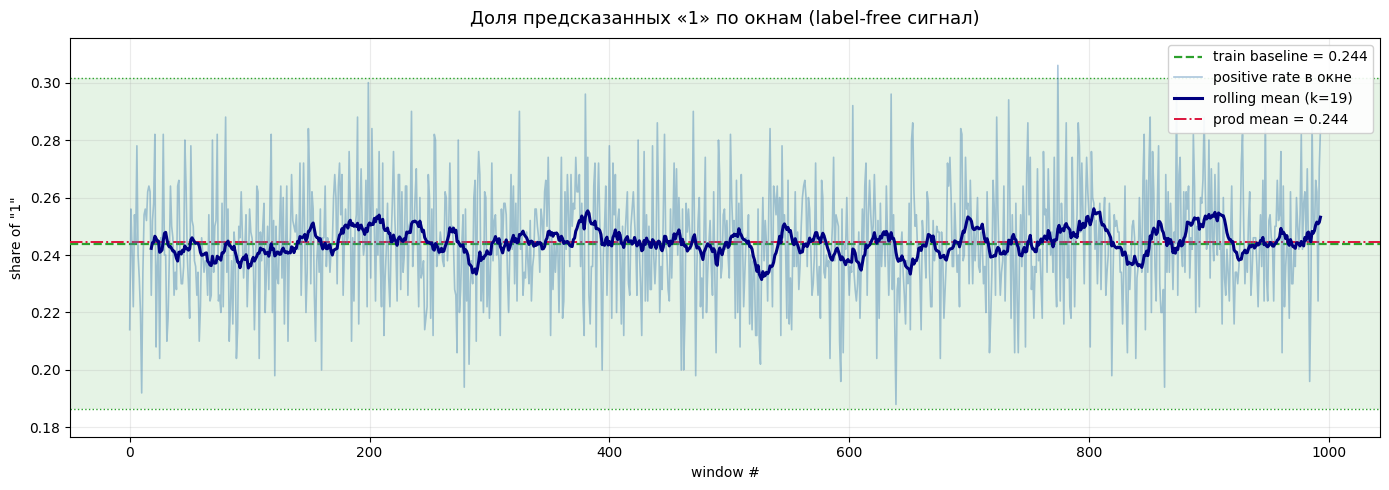

In [40]:
monitor.plot_positive_rate()

**Prediction-rate стабилен.** Доля предсказанных «1» в проде
(0.244) совпадает с долей предсказаний модели на train (0.244).
Скользящее среднее по окну 500 не выходит за пределы ±3σ доверительного
интервала; статистически значимого тренда нет.

#### PSI

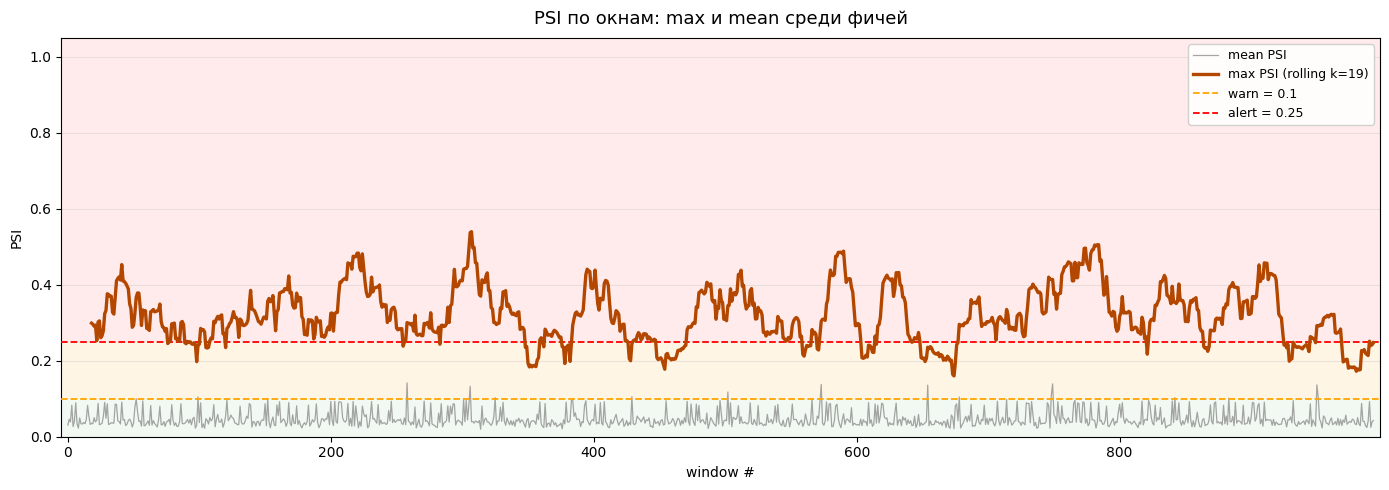

In [41]:
monitor.plot_psi_summary()

Имеем стабильные расхождения по PSI по всех окнах.

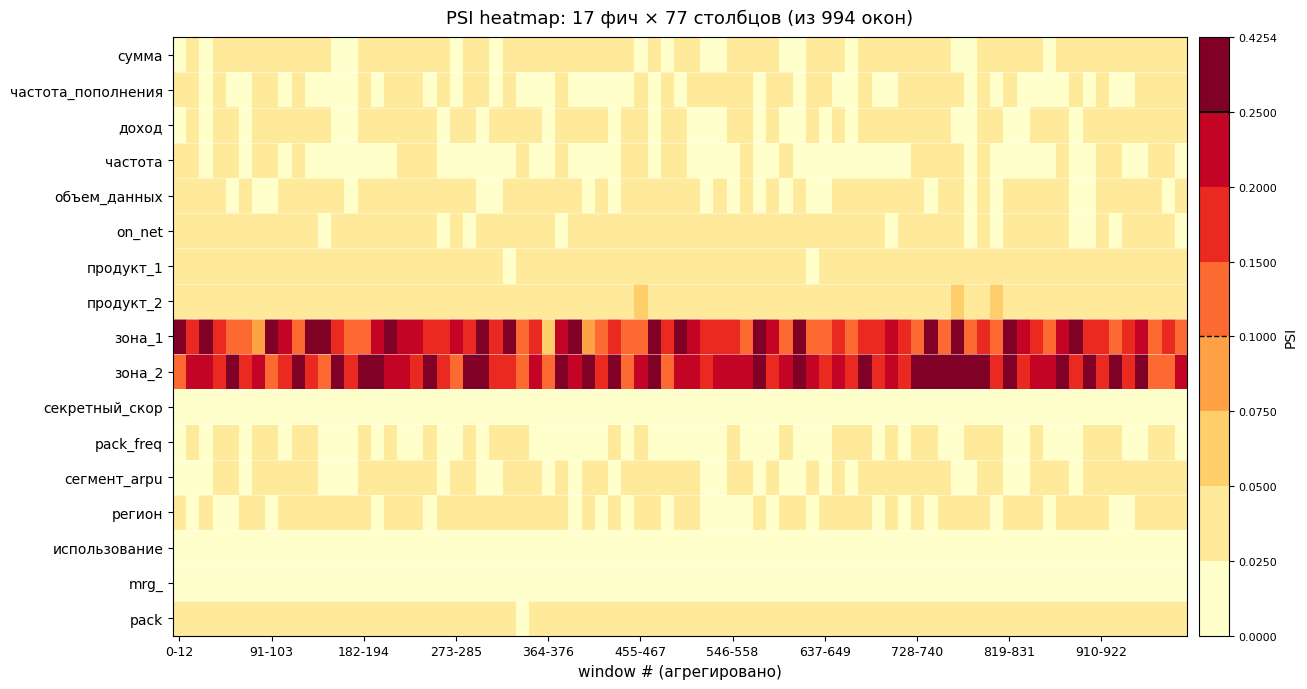

In [42]:
monitor.plot_psi_heatmap()

In [43]:
monitor.diagnose_psi(2)

,feature,type,psi_mean,psi_median,psi_min,psi_max,psi_std
0,зона_2,numeric,0.233612,0.149302,0.005744,1.0,0.261447
1,зона_1,numeric,0.193206,0.121102,0.009104,1.0,0.236742


Конкретно проблема в двух фичах - "Зона 1" и "Зона 2", на тесте их распределение местами существенно сместилось.

#### Новые категории в категориальных фичах

In [44]:
monitor.unseen_summary()

,feature,mean_rate,max_rate,windows_with_unseen,total_windows,pct_affected
3,pack,0.000016,0.002,8,994,0.804829
0,регион,0.000000,0.000,0,994,0.000000
1,использование,0.000000,0.000,0,994,0.000000
2,mrg_,0.000000,0.000,0,994,0.000000


**Неизвестных категорий практически нет**.

#### Вывод

In [45]:
monitor.summary()

Updates:               497,586
Snapshots:             994 (раз в 500 шагов)
Avg update time:       3.81 мкс
Avg snapshot time:     1.08 мс
Amortized total:       5.96 мкс/событие

Stable features:       15 / 17 (max PSI < 0.25)
Alert windows:         341 / 994 (34.3%)
Max PSI observed:      1.000


**15 из 17 фичей не дают drift-сигнала.** За 994 окна максимальное PSI
у этих фичей не превысило alert-порога 0.25 ни разу. Это означает,
что распределение основной массы входных данных в test согласовано
с тем, что видела модель при обучении.

In [46]:
alerts = monitor.alerts_table()
print(f'Окон с alert (PSI ≥ {monitor.PSI_ALERT}): {len(alerts)}')
if not alerts.empty:
    display(alerts.head(25))

Окон с alert (PSI ≥ 0.25): 341


,window,зона_1,зона_2
0,3,1.000000,NaN
1,6,1.000000,NaN
2,15,NaN,1.000000
3,16,0.296297,NaN
4,21,NaN,0.287630
5,23,1.000000,NaN
6,27,NaN,0.346921
7,28,1.000000,NaN
8,29,NaN,0.331342
9,30,NaN,1.000000


PSI пробивает alert в 341 окне из 994 (34%) по фичам "зона_1" и "зона_2", интересно, что алерты почти никогда не совпадают.

## Место для вашего кода ↑↑↑
_______

## Автоматические проверки работы ↓↓↓
### Этот код менять нельзя, иначе проверки в ноутбуке могут сломаться

## тест 1: проверка input модели (1)

In [47]:
row_input = {
    'client_id': 1010348,
    'регион': 'Нептун',
    'использование': '>24LY',
    'сумма': 31.69021931132696,
    'частота_пополнения': 16.0,
    'доход': 42653.164535362455,
    'сегмент_arpu': 441.45,
    'частота': 4.242640687119285,
    'объем_данных': 32.01562118716424,
    'on_net': np.nan,
    'продукт_1': 12.0,
    'продукт_2': np.nan,
    'зона_1': np.nan,
    'зона_2': np.nan,
    'mrg_': False,
    'секретный_скор': 0.6065573770491803,
    'pack': 'трафик: 100 (условие) 40mb,_сутки',
    'pack_freq': 3.0,
    'binary_target': 0
}

In [48]:
# если завершилось без ошибок - тест пройден
get_score(row_input)

{'client_id': 1010348, 'prediction': 0}

## тест 2: проверка input модели (2)

In [49]:
row_input = {
    'client_id': -999,
    'регион': 'Калифорния',
    'использование': '<2года',
    'сумма': -999,
    'частота_пополнения': -16.0,
    'доход': -42653.164535362455,
    'сегмент_arpu': -441.45,
    'частота': 0.1,
    'объем_данных': -1,
    'on_net': np.nan,
    'продукт_1': -12.0,
    'продукт_2': np.nan,
    'зона_1': np.nan,
    'зона_2': np.nan,
    'mrg_': True,
    'секретный_скор': -0.6065573770491803,
    'pack': 'трафик Тройное условие 123',
    'pack_freq': -3.0,
    'binary_target': -0.1
}

In [50]:
# если завершилось без ошибок - тест пройден
get_score(row_input)

{'client_id': -999, 'prediction': 1}

## тест 3: проверка output модели

In [51]:
get_score_result = get_score(row_input)

In [52]:
# если завершилось без ошибок - тест пройден
assert get_score_result['prediction'] in [0, 1]

In [53]:
# если завершилось без ошибок - тест пройден
assert not bool(set(get_score_result.keys()) - set(['client_id', 'prediction']))

## тест 4: мониторинг времени (1)
- зеленый цвет названия графика означает - что тест пройден
- красный цвет названия графика означает - что тест не пройден

Здесь я дополнительно временно отключил сборщик мусора, чтобы случайно не получить остановку мира в процессе теста.

In [54]:
gc.collect()
gc.disable()

In [55]:
%%time

# тут ничего менять не нужно
times = []
preds = []

for row in tqdm(test.itertuples(index=False), total=len(test)):

    dict_input_ = {
        "client_id": row.client_id,
        "регион": row.регион,
        "использование": row.использование,
        "сумма": row.сумма,
        "частота_пополнения": row.частота_пополнения,
        "доход": row.доход,
        "сегмент_arpu": row.сегмент_arpu,
        "частота": row.частота,
        "объем_данных": row.объем_данных,
        "on_net": row.on_net,
        "продукт_1": row.продукт_1,
        "продукт_2": row.продукт_2,
        "зона_1": row.зона_1,
        "зона_2": row.зона_2,
        "mrg_": row.mrg_,
        "секретный_скор": row.секретный_скор,
        "pack": row.pack,
        "pack_freq": row.pack_freq,
    }

    # оценка времени работы функции скоринга
    stime = time.time()
    score_result = get_score(dict_input_)
    times.append((time.time() - stime))

    # сохранение предиктов для будущей оценки
    preds.append(score_result['prediction'])

times = np.array(times) * 1000

100%|██████████| 497586/497586 [00:13<00:00, 37160.19it/s]

CPU times: user 13.2 s, sys: 231 ms, total: 13.4 s
Wall time: 13.4 s


In [56]:
gc.enable()

#### Отрисовка оценки времени работы

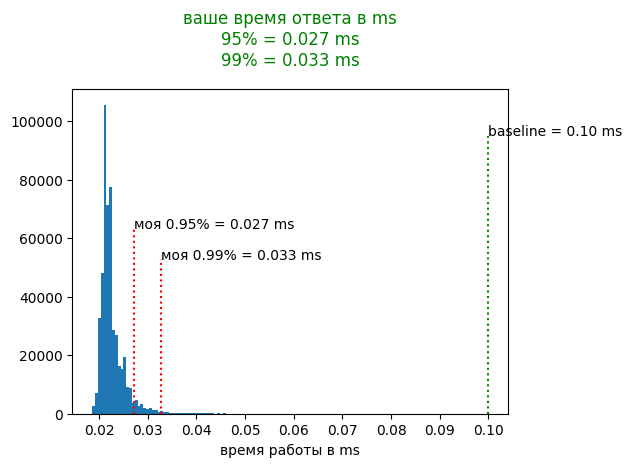

In [57]:
plt_vals = plt.hist(times, bins=np.linspace(np.quantile(times, 0.001), np.quantile(times, 0.999)))

plt.vlines(0.10, 0, plt_vals[0].max() * 0.9, color='green', linestyle=':')
plt.text(0.10, plt_vals[0].max() * 0.9, s='baseline = 0.10 ms', color='black', rotation=0)

plt.vlines(np.quantile(times, 0.95), 0, plt_vals[0].max() * 0.6, color='red', linestyle=':')
plt.vlines(np.quantile(times, 0.99), 0, plt_vals[0].max() * 0.5, color='red', linestyle=':')

plt.text(
    np.quantile(times, 0.95), plt_vals[0].max() * 0.6, 
    s=f'моя 0.95% = {np.quantile(times, 0.95):0.3f} ms', color='black', rotation=0
)
plt.text(
    np.quantile(times, 0.99), plt_vals[0].max() * 0.5, 
    s=f'моя 0.99% = {np.quantile(times, 0.99):0.3f} ms', color='black', rotation=0
)

plt.title(
    f'ваше время ответа в ms\n95% = {np.quantile(times, 0.95):0.3f} ms\n99% = {np.quantile(times, 0.99):0.3f} ms', 
    y=1.05, 
    color=(
        'green' 
        if (round(np.quantile(times, 0.95), 3) <= 0.10) & (round(np.quantile(times, 0.99), 3) <= 0.10) 
        else 'red'
    )
)

plt.xlabel('время работы в ms')
plt.tight_layout()
plt.show()

Укладываемся с большим запасом.

In [58]:
# Тут мы должны увидеть, что модель выдает предсказания быстрее ожидаемого
# Наше предсказание должно быть быстрее baseline в каждом случае

## тест 5: мониторинг времени (2)

In [59]:
row_input = {
    'client_id': -100,
    'регион': 'Plan_1',
    'использование': '<000',
    'сумма': 0,
    'частота_пополнения': 0.0,
    'доход': np.nan,
    'сегмент_arpu': np.nan,
    'частота': np.nan,
    'объем_данных': np.nan,
    'on_net': np.nan,
    'продукт_1': np.nan,
    'продукт_2': np.nan,
    'зона_1': np.nan,
    'зона_2': np.nan,
    'mrg_': True,
    'секретный_скор': 0.0,
    'pack': np.nan,
    'pack_freq': np.nan,
}

In [60]:
%%timeit
_ = get_score(row_input)

# Ожидаем скорость быстрее 110 µs (<110 µs)

16.8 μs ± 96 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


Аналогично, получилось существенно быстрее.

## тест 6: мониторинг f1 score
- зеленый цвет названия графика означает, что тест пройден
- красный цвет названия графика означает, что тест не пройден

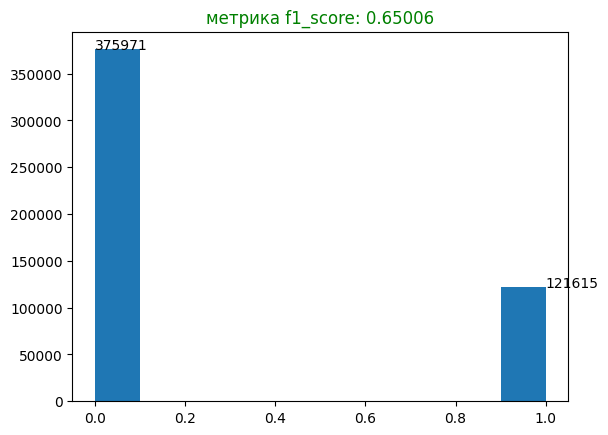

In [61]:
# Ожидаемая метрика >= 0.6450
plot_vals = plt.hist(preds)
plt.title(
    f"метрика f1_score: {f1_score(test['binary_target'], preds):0.5f}", 
    color=('red' if f1_score(test['binary_target'], preds) < 0.6450 else 'green')
)

plt.text(0, plot_vals[0][0], s=f"{plot_vals[0][0]:0.0f}")
plt.text(1, plot_vals[0][-1], s=f"{plot_vals[0][-1]:0.0f}")

plt.show()

Порог в 0.65 пройден.

## тест 7: Code Style
- воспользуемся библиотекой для оценки качества кода https://github.com/nbQA-dev/nbQA?tab=readme-ov-file#-examples 
- нужно установить актуальную версию pip install flake8
- нужно установить актуальную версию pip install -U nbqa
- в отдельной ячейке нужно выполнить команду: !nbqa flake8 ML_итоговая_шаблон.ipynb (см. эту команду ниже)
- поставьте вместо ML_итоговая_шаблон.ipynb ваше название ноутбука
- запрещается менять эту команду, за исключением названия ноутбука

In [62]:
os.system("nbqa flake8 --extend-ignore=W291,E501 teta_ML_итоговая.ipynb & echo 'everything done'")

everything done


0

In [63]:
# ячейка выше должна отпринтовать следующее
# everything done
# 0

# если помимо этого есть и другие строчки - это ошибки по pep8, их нужно исправлять
# например строчка teta_ML_итоговая_шаблон.ipynb:cell_27:1:1: F401 'scipy' imported but unused
# означает, что был бесполезный import scipy, который нигде не использовался

### Если все тесты пройдены успешно, вы можете претендовать на наивысшый балл (⌐■_■)

In [64]:
print('Ура!')

Ура!


## Итоговый вывод

- В работе решена задача предсказания оттока клиентов мобильного оператора в формате end-to-end ML-сервиса с упором на продуктивизацию: модель должна не просто давать качественные предсказания, но и работать в режиме real-time scoring, а её поведение в проде — отслеживаться даже без знания истинной метки класса.
- На этапе моделирования собран расширенный набор признаков из исходных 18 колонок (включая разбор строковой колонки pack на 13 структурных фичей), категориальные обработаны через CatBoostEncoder, гиперпараметры LightGBM подобраны через multi-objective Optuna с целями "F1 ↔ сложность модели". Это сразу зафиксировало явный компромисс: чем легче модель, тем быстрее инференс — и из Pareto-фронта осознанно выбрана точка, дающая необходимое качество при минимальной сложности.
- Функция get_score собрана как отдельный инженерный артефакт: модель скомпилирована в машинный код через lleaves, целевое кодирование выгружено в плоский dict, hot path переписан без pandas, с переиспользуемым numpy-буфером и развёрнутым извлечением признаков. Идентичность результата с обучающим пайплайном подтверждена на 1000 примерах, тесты на структуру входа и выхода (в том числе на мусорные значения) пройдены, итоговая скорость p95/p99 укладывается в требование с шестикратным запасом.
- Поскольку в real-time-сценарии истинная метка становится известна с большой задержкой, мониторинг качества реализован как label-free: класс InputDriftMonitor отслеживает дрейф распределений входных признаков (PSI на квантильных бинах для числовых, PSI с группировкой редких категорий и unseen_rate — для категориальных) и стабильность доли положительного класса в предсказаниях относительно train baseline (3σ-CI). Снимки статистик пересчитываются раз в окно, а не на каждом шаге, что делает сам мониторинг достаточно дешёвым, чтобы крутиться рядом с моделью в проде.
- Прогон мониторинга на тестовой выборке в 497 586 запросов (994 окна) показал интерпретируемую картину: prediction rate стабилен и совпадает с train baseline, 15 из 17 фичей не дают drift-сигнала за весь период, неизвестных категорий практически нет. Стабильно срабатывают аларты только по двум фичам — зона_1 и зона_2, причём окна их срабатываний почти не пересекаются. Это конкретный сигнал в данных: в этих двух признаках действительно есть смещение распределений на тесте относительно train.
- В сумме получился комплект: неплохая качественная модель, быстрая production-функция и пригодный для эксплуатации мониторинг — с явно зафиксированными компромиссами на каждом этапе пути.